# PHÂN LOẠI LỚP PHỦ RỪNG COVERTYPE — LR VÀ RF
**Nhóm 11 · Phân tích dữ liệu lớn · Cách trình bày theo bài TH4**

Viết trực tiếp từng bước: đọc dữ liệu → khảo sát → chia tập → tạo Pipeline →
Cross-Validation → GridSearchCV → predict → đánh giá và so sánh.
Không dùng lớp đo tài nguyên hoặc các hàm bọc huấn luyện/đánh giá.

Giữ **3-fold CV**, LR **16 cấu hình** và RF **16 cấu hình** trên toàn bộ Train.
Hai thuật toán dùng cùng Train/Test, cùng fold, cùng máy và tối đa 2 luồng.
Phần lưu mô hình, fingerprint và xuất tệp nằm ở phụ lục cuối.

**Bản này đã hoàn tất thực nghiệm LR và RF, có đầy đủ kết quả và output được lưu trong notebook.**
Hình thiết kế ghi 5-fold; thực nghiệm này sử dụng 3-fold đã thống nhất.

### Chuẩn bị thư viện
Nếu môi trường thiếu thư viện, chạy `%pip install ucimlrepo numpy pandas matplotlib seaborn scikit-learn joblib threadpoolctl`.
Import trước để các cell dữ liệu chạy được; phần 4 tổng hợp lại môi trường.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from pathlib import Path
from datetime import datetime
from time import perf_counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEED = 42
N_SPLITS = 3
N_JOBS = 2

## 1. Bộ dữ liệu đầu vào
Covertype gồm **581.012 mẫu, 54 đặc trưng, 7 lớp**. Tải trực tiếp từ UCI bằng
`fetch_ucirepo(id=31)`, giống cách nạp dữ liệu trong bài thực hành.
Nguồn đã có tên cột; sau khi tải mới phân nhóm cột. Không one-hot lại 44 cột nhị phân.

In [2]:
%pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

covertype = fetch_ucirepo(id=31)
X = covertype.data.features.astype(np.float32)
y = covertype.data.targets.squeeze().astype(np.int8)

df = X.copy()
df['Cover_Type'] = y
print('Kích thước:', df.shape)
display(df.head())
df.info()

Kích thước: (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Cover_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           581012 non-null  float32
 1   Aspect                              581012 non-null  float32
 2   Slope                               581012 non-null  float32
 3   Horizontal_Distance_To_Hydrology    581012 non-null  float32
 4   Vertical_Distance_To_Hydrology      581012 non-null  float32
 5   Horizontal_Distance_To_Roadways     581012 non-null  float32
 6   Hillshade_9am                       581012 non-null  float32
 7   Hillshade_Noon                      581012 non-null  float32
 8   Hillshade_3pm                       581012 non-null  float32
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  float32
 10  Wilderness_Area1                    581012 non-null  float32
 11  Soil_Type1                

In [4]:
cot_vung_rung = [c for c in X.columns if c.startswith('Wilderness_Area')]
cot_loai_dat = [c for c in X.columns if c.startswith('Soil_Type')]
cot_nhi_phan = cot_vung_rung + cot_loai_dat
cot_so = [c for c in X.columns if c not in cot_nhi_phan]
features = X.columns.tolist()
class_names = ['Spruce/Fir', 'Lodgepole Pine', 'Ponderosa Pine',
               'Cottonwood/Willow', 'Aspen', 'Douglas-fir', 'Krummholz']
labels = np.arange(1, 8)
print('Số cột số:', len(cot_so), '| Số cột nhị phân:', len(cot_nhi_phan))
assert len(cot_so) == 10 and len(cot_vung_rung) == 4 and len(cot_loai_dat) == 40

Số cột số: 10 | Số cột nhị phân: 44


## 2. Khảo sát và phân tích dữ liệu (EDA)
Kiểm tra chất lượng nguồn. Để giữ Test độc lập, tách holdout ngay trước EDA;
các biểu đồ và thống kê mô tả bên dưới dùng **Train**. Phần 3 giải thích và kiểm tra cách chia.

In [5]:
print('Tổng ô thiếu:', df.isnull().sum().sum())
print('Số dòng trùng:', df.duplicated().sum())
assert df.shape == (581012, 55)
assert np.array_equal(np.sort(df['Cover_Type'].unique()), labels)
assert np.isfinite(df[features].to_numpy()).all()
assert df[cot_nhi_phan].isin([0, 1]).all().all()
assert df[cot_vung_rung].sum(axis=1).eq(1).all(), 'Nhóm Wilderness_Area không hợp lệ.'
assert df[cot_loai_dat].sum(axis=1).eq(1).all(), 'Nhóm Soil_Type không hợp lệ.'

Tổng ô thiếu: 0
Số dòng trùng: 0


In [6]:
X = df[features]
y = df['Cover_Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (464809, 54) | Test: (116203, 54)


### 2.1. Thống kê mô tả và phân bố 7 lớp

,count,mean,std,min,25%,50%,75%,max
Elevation,464809.0,2959.510254,279.988647,1860.0,2809.0,2996.0,3164.0,3858.0
Aspect,464809.0,155.828568,111.968201,0.0,58.0,127.0,261.0,360.0
Slope,464809.0,14.104561,7.486888,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,464809.0,269.348358,212.376556,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,464809.0,46.420753,58.232655,-166.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,464809.0,2351.818115,1559.205444,0.0,1106.0,1999.0,3331.0,7117.0
Hillshade_9am,464809.0,212.130142,26.761314,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,464809.0,223.316498,19.764175,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,464809.0,142.546127,38.265263,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,464809.0,1979.968018,1323.535400,0.0,1024.0,1710.0,2550.0,7172.0


,Tên lớp,Số mẫu Train,Tỷ lệ (%)
Cover_Type,,,
1,Spruce/Fir,169472,36.460568
2,Lodgepole Pine,226640,48.759813
3,Ponderosa Pine,28603,6.153710
4,Cottonwood/Willow,2198,0.472882
5,Aspen,7594,1.633789
6,Douglas-fir,13894,2.989185
7,Krummholz,16408,3.530052


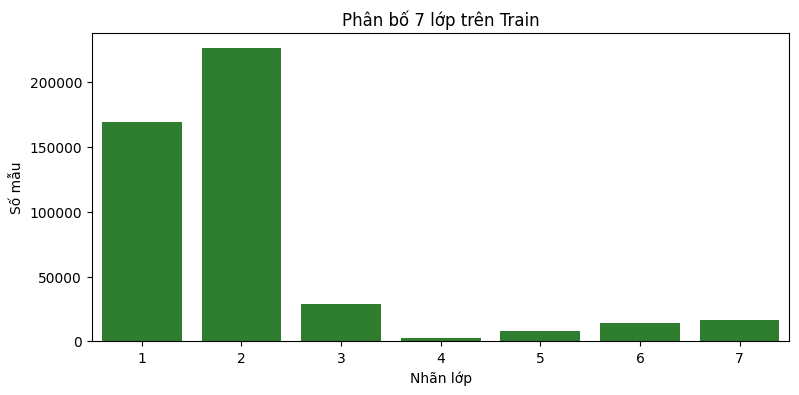

In [7]:
display(X_train[cot_so].describe().T)

counts = y_train.value_counts().sort_index()
distribution = pd.DataFrame({'Tên lớp': class_names, 'Số mẫu Train': counts,
                              'Tỷ lệ (%)': counts / len(y_train) * 100})
display(distribution)

plt.figure(figsize=(9, 4))
sns.countplot(x=y_train, color='forestgreen')
plt.title('Phân bố 7 lớp trên Train')
plt.xlabel('Nhãn lớp')
plt.ylabel('Số mẫu')
plt.show()

### 2.2. Phân bố đặc trưng, tương quan và độ cao theo lớp

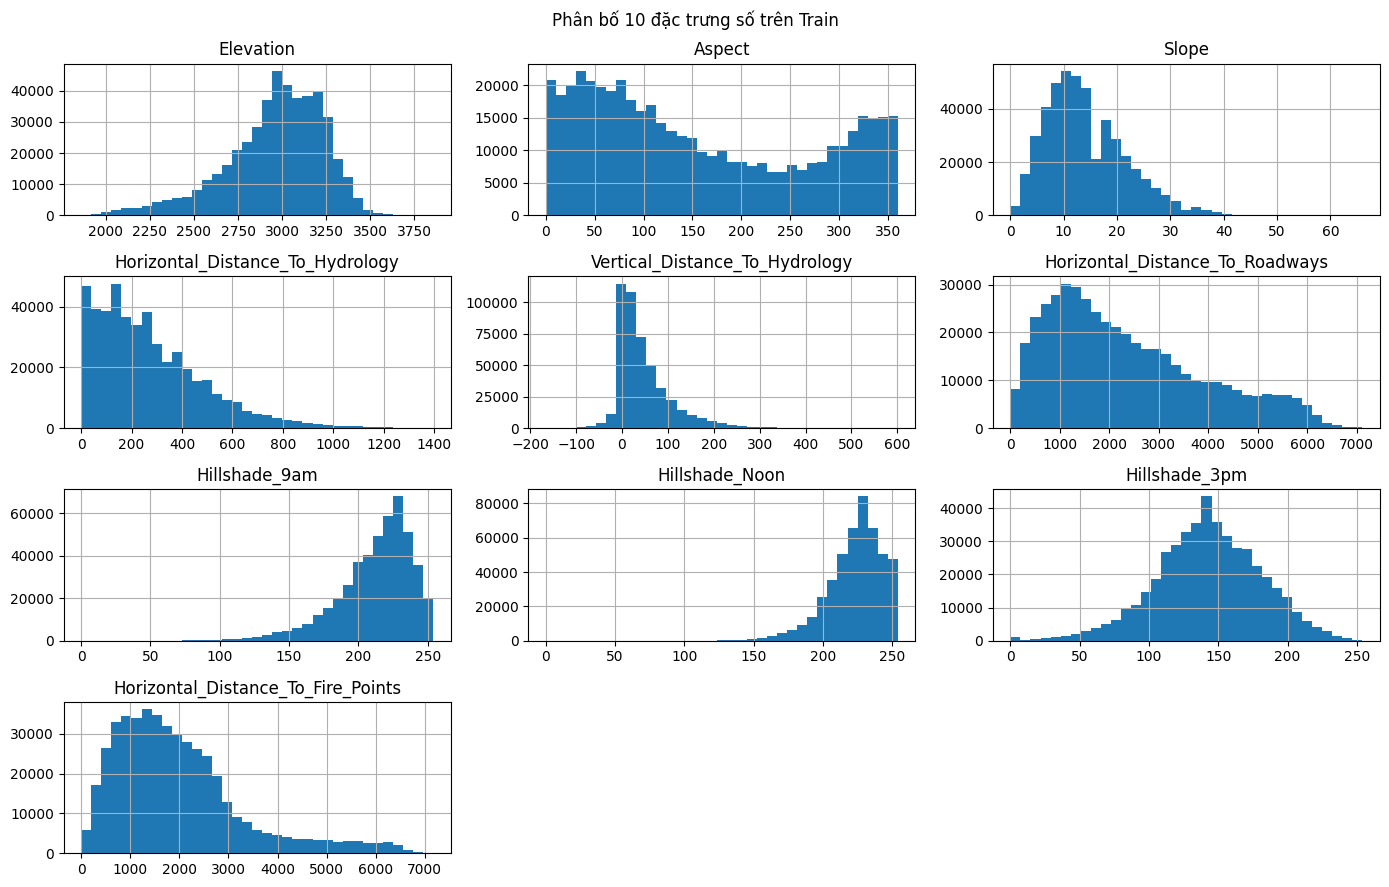

In [8]:
X_train[cot_so].hist(bins=35, figsize=(14, 9))
plt.suptitle('Phân bố 10 đặc trưng số trên Train')
plt.tight_layout()
plt.show()

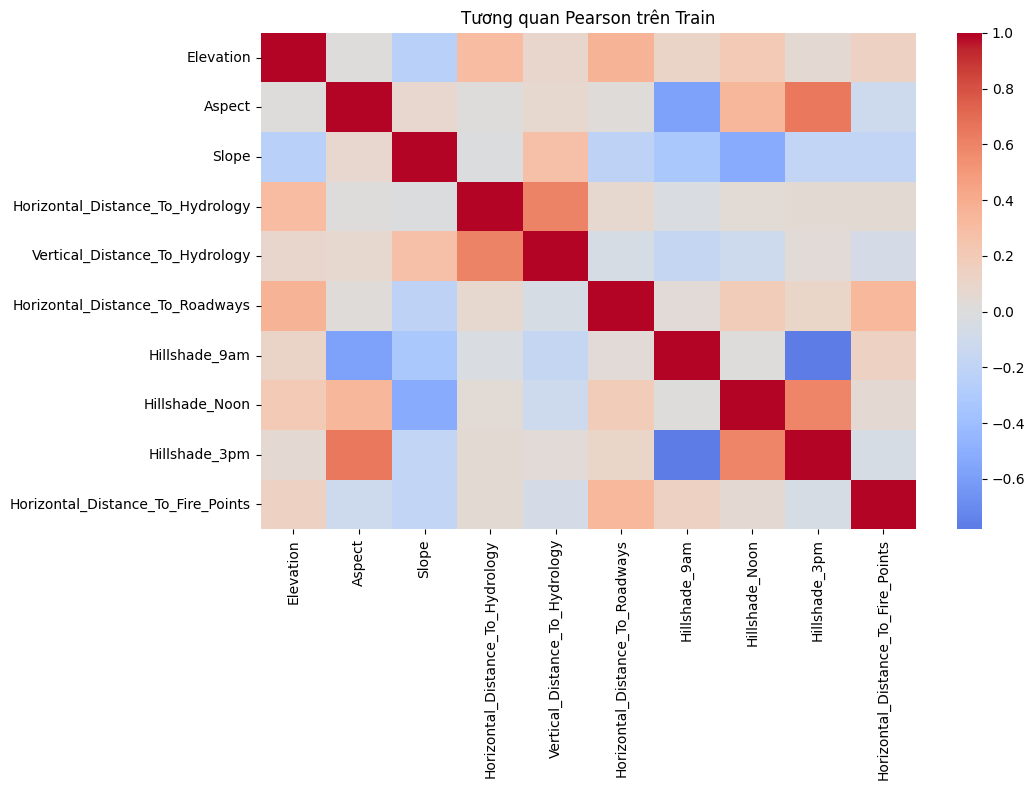

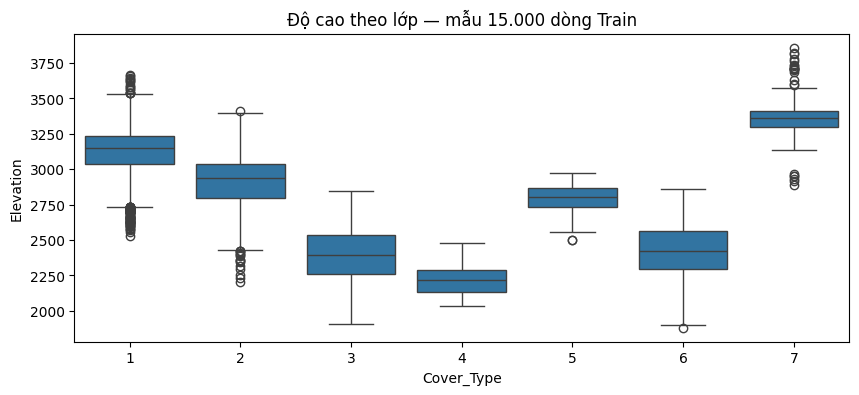

In [9]:
plt.figure(figsize=(11, 8))
sns.heatmap(X_train[cot_so].corr(), cmap='coolwarm', center=0)
plt.title('Tương quan Pearson trên Train')
plt.tight_layout()
plt.show()

sample = X_train[['Elevation']].assign(Cover_Type=y_train).sample(15000, random_state=SEED)
plt.figure(figsize=(10, 4))
sns.boxplot(data=sample, x='Cover_Type', y='Elevation')
plt.title('Độ cao theo lớp — mẫu 15.000 dòng Train')
plt.show()

## 3. Tiền xử lý và chia dữ liệu
Holdout 80/20, phân tầng theo y, seed=42: **464.809 Train / 116.203 Test**.
LR và RF dùng đúng các biến Train/Test đã tạo, không chia lại riêng từng mô hình.
Không xóa trùng/ngoại lệ cơ học và không resampling. Tiền xử lý học tham số đặt trong Pipeline.

In [10]:
train_idx = X_train.index.to_numpy(dtype=np.int64)
test_idx = X_test.index.to_numpy(dtype=np.int64)
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(train_idx) + len(test_idx) == len(df)

# Đối chiếu chỉ số với split đã lưu nếu có; không ghi đè phiên cũ.
split_path = Path('Covertype_RF_LR/shared_split.npz')
if split_path.exists():
    with np.load(split_path, allow_pickle=False) as split:
        np.testing.assert_array_equal(train_idx, split['train_idx'])
        np.testing.assert_array_equal(test_idx, split['test_idx'])

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(skf.split(X_train, y_train))
print('Hai mô hình dùng chung', len(cv_splits), 'fold trên toàn bộ Train.')

Hai mô hình dùng chung 3 fold trên toàn bộ Train.


## 4. Công cụ và thư viện
Python/scikit-learn xử lý trên một máy; pandas/NumPy quản lý dữ liệu,
matplotlib/seaborn vẽ biểu đồ. Dùng `perf_counter` đo thời gian trực tiếp.

In [11]:
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('Seed:', SEED, '| CV:', N_SPLITS, 'fold | Giới hạn luồng:', N_JOBS)

scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
Seed: 42 | CV: 3 fold | Giới hạn luồng: 2


## 5. Xây dựng Pipeline và mô hình
### 5.1. Logistic Regression
10 biến số: điền trung vị → StandardScaler. 44 biến nhị phân: điền mode, không chuẩn hóa.
Đặt các bước trong Pipeline để mỗi fold chỉ học tiền xử lý từ phần Train của fold đó.

In [12]:
pipeline_so = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
pipeline_nhi_phan = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])
preprocessor = ColumnTransformer([
    ('so', pipeline_so, cot_so),
    ('nhi_phan', pipeline_nhi_phan, cot_nhi_phan)
])
pipe_lr = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(C=1.0, class_weight=None, solver='lbfgs',
                               max_iter=1000, random_state=SEED))
])
pipe_lr

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('so',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Elevation', 'Aspect',
                                                   'Slope',
                                                   'Horizontal_Distance_To_Hydrology',
                                                   'Vertical_Distance_To_Hydrology',
                                                   'Horizontal_Distance_To_Roadways',
                                                   'Hillshade_9am',
                                                   'Hillshade_Noon',
                                                   'Hillshade_3pm',
                                                   'Horizontal_Dist...
                                                   'Soil_Type5', 'Soil_Type6',
                                                   'Soil_Type7', 'Soil_Type8',
                                                   'Soil_Type9', 'Soil_Type10',
                                                   'Soil_Type11', 'Soil_Type12',
                                                   'Soil_Type13', 'Soil_Type14',
                                                   'Soil_Type15', 'Soil_Type16',
                                                   'Soil_Type17', 'Soil_Type18',
                                                   'Soil_Type19', 'Soil_Type20',
                                                   'Soil_Type21', 'Soil_Type22',
                                                   'Soil_Type23', 'Soil_Type24',
                                                   'Soil_Type25', 'Soil_Type26', ...])])),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

### 5.2. Random Forest

Giữ nguyên 54 đặc trưng, không chuẩn hóa. Baseline: 100 cây, không giới hạn độ sâu.

In [13]:
pipe_rf = Pipeline([
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=None,
                                   max_features='sqrt', min_samples_leaf=1,
                                   class_weight=None, random_state=SEED, n_jobs=N_JOBS))
])
pipe_rf

Pipeline(steps=[('clf', RandomForestClassifier(n_jobs=2, random_state=42))])

## 6. Tối ưu mô hình: Cross-Validation + Grid Search
Tương tự TH4: dùng `cross_validate` xem baseline, sau đó tạo `GridSearchCV` cho từng Pipeline.
Chọn cấu hình theo **Macro-F1 trên CV**; Test không tham gia tìm tham số.

### 6.1. Đánh giá chéo hai mô hình cơ sở

In [14]:
models = {'LR': pipe_lr, 'RF': pipe_rf}
scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
cv_baseline = {}
rows_cv = []

for name, model in models.items():
    with threadpool_limits(limits=N_JOBS):
        scores = cross_validate(model, X_train, y_train, cv=cv_splits,
                                 scoring=scoring, n_jobs=1, return_train_score=True,
                                 error_score='raise')
    cv_baseline[name] = scores
    rows_cv.append({'Mô hình': name,
                    'CV Macro-F1': scores['test_f1_macro'].mean(),
                    'Độ lệch chuẩn': scores['test_f1_macro'].std(),
                    'Train Macro-F1': scores['train_f1_macro'].mean()})

display(pd.DataFrame(rows_cv))

,Mô hình,CV Macro-F1,Độ lệch chuẩn,Train Macro-F1
0,LR,0.532514,0.004346,0.532607
1,RF,0.911703,0.000335,0.999999


### 6.2. Grid Search cho LR
8 giá trị C × 2 lựa chọn class_weight = **16 cấu hình × 3 fold = 48 lượt CV**.
Solver lbfgs dùng L2. `refit=True` tự fit cấu hình tốt nhất trên toàn bộ Train.

In [15]:
param_grid_lr = {
    'clf__C': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0],
    'clf__class_weight': [None, 'balanced']
}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv_splits, scoring='f1_macro',
                       n_jobs=1, refit=True, return_train_score=True,
                       error_score='raise', verbose=2)

In [16]:
import warnings
from sklearn.exceptions import ConvergenceWarning

start = perf_counter()
with warnings.catch_warnings(), threadpool_limits(limits=N_JOBS):
    warnings.simplefilter('error', ConvergenceWarning)
    grid_lr.fit(X_train, y_train)
search_time_lr = perf_counter() - start

print('Tham số LR tốt nhất:', grid_lr.best_params_)
print('Macro-F1 CV LR:', grid_lr.best_score_)
print('Thời gian tìm kiếm LR:', round(search_time_lr, 2), 'giây')

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=  11.3s
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=  11.7s
[CV] END ..............clf__C=0.0001, clf__class_weight=None; total time=  12.8s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=   7.6s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=  10.6s
[CV] END ..........clf__C=0.0001, clf__class_weight=balanced; total time=  10.8s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=  18.9s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=  20.6s
[CV] END ...............clf__C=0.001, clf__class_weight=None; total time=  16.5s
[CV] END ...........clf__C=0.001, clf__class_weight=balanced; total time=  17.4s
[CV] END ...........clf__C=0.001, clf__class_weight=balanced; total time=  17.7s
[CV] END ...........clf__C=0.001, clf__class_wei

In [17]:
df_grid_lr = pd.DataFrame(grid_lr.cv_results_).sort_values('rank_test_score')
display(df_grid_lr[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(5))

,params,mean_test_score,std_test_score,rank_test_score
12,"{'clf__C': 100.0, 'clf__class_weight': None}",0.534284,0.003943,1
10,"{'clf__C': 10.0, 'clf__class_weight': None}",0.533879,0.004467,2
14,"{'clf__C': 1000.0, 'clf__class_weight': None}",0.533531,0.004689,3
8,"{'clf__C': 1.0, 'clf__class_weight': None}",0.532514,0.004346,4
6,"{'clf__C': 0.1, 'clf__class_weight': None}",0.524337,0.004562,5


### 6.3. Grid Search cho RF

2 × 2 × 2 × 2 = **16 cấu hình × 3 fold = 48 lượt CV**, sau đó refit tốt nhất.

In [18]:
param_grid_rf = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [20, None],
    'clf__max_features': ['sqrt', 0.5],
    'clf__min_samples_leaf': [1, 3]
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_splits, scoring='f1_macro',
                       n_jobs=1, refit=True, return_train_score=True,
                       error_score='raise', verbose=2)

In [19]:
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    grid_rf.fit(X_train, y_train)
search_time_rf = perf_counter() - start

print('Tham số RF tốt nhất:', grid_rf.best_params_)
print('Macro-F1 CV RF:', grid_rf.best_score_)
print('Thời gian tìm kiếm RF:', round(search_time_rf, 2), 'giây')

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time= 1.3min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time= 1.4min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=100; total time= 1.3min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 2.7min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 2.9min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=1, clf__n_estimators=200; total time= 2.7min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=3, clf__n_estimators=100; total time= 1.3min
[CV] END clf__max_depth=20, clf__max_features=sqrt, clf__min_samples_leaf=3, clf__n_estimators=100; total 

In [20]:
df_grid_rf = pd.DataFrame(grid_rf.cv_results_).sort_values('rank_test_score')
display(df_grid_rf[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(5))

,params,mean_test_score,std_test_score,rank_test_score
13,"{'clf__max_depth': None, 'clf__max_features': ...",0.932816,0.000757,1
12,"{'clf__max_depth': None, 'clf__max_features': ...",0.932386,0.000865,2
15,"{'clf__max_depth': None, 'clf__max_features': ...",0.924484,0.001011,3
14,"{'clf__max_depth': None, 'clf__max_features': ...",0.923644,0.001083,4
9,"{'clf__max_depth': None, 'clf__max_features': ...",0.912094,0.000609,5


## 7. Đánh giá và so sánh kết quả
### 7.1. Huấn luyện baseline và lấy mô hình tốt nhất
`cross_validate` chỉ fit bản sao trong các fold; cần fit lại hai baseline trên toàn bộ Train.
Hai mô hình tối ưu đã được Grid Search refit. Không chọn lại tham số theo Test.

In [21]:
lr_before = clone(pipe_lr)
start = perf_counter()
with warnings.catch_warnings(), threadpool_limits(limits=N_JOBS):
    warnings.simplefilter('error', ConvergenceWarning)
    lr_before.fit(X_train, y_train)
fit_time_lr = perf_counter() - start

rf_before = clone(pipe_rf)
start = perf_counter()
with threadpool_limits(limits=N_JOBS):
    rf_before.fit(X_train, y_train)
fit_time_rf = perf_counter() - start

best_lr = grid_lr.best_estimator_
best_rf = grid_rf.best_estimator_
print('LR tối ưu:', grid_lr.best_params_)
print('RF tối ưu:', grid_rf.best_params_)

LR tối ưu: {'clf__C': 100.0, 'clf__class_weight': None}
RF tối ưu: {'clf__max_depth': None, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}


### 7.2. Dự đoán trên Test

Đo predict 3 lần trên cùng Test, lấy trung vị cho cả bốn mô hình.

In [22]:
models = {'lr_before': lr_before, 'lr_after': best_lr,
          'rf_before': rf_before, 'rf_after': best_rf}
predictions = {}
predict_times = {}

for name, model in models.items():
    times = []
    with threadpool_limits(limits=N_JOBS):
        for repeat in range(3):
            start = perf_counter()
            y_pred = model.predict(X_test)
            times.append(perf_counter() - start)
    predictions[name] = y_pred
    predict_times[name] = float(np.median(times))

y_pred_lr = predictions['lr_after']
y_pred_rf = predictions['rf_after']

### 7.3. Đánh giá LR và RF tối ưu — gọi metric trực tiếp như TH4

In [23]:
print('LOGISTIC REGRESSION TỐI ƯU')
print('Accuracy:', accuracy_score(y_test, y_pred_lr))
print('Precision macro:', precision_score(y_test, y_pred_lr, average='macro', zero_division=0))
print('Recall macro:', recall_score(y_test, y_pred_lr, average='macro', zero_division=0))
print('Macro-F1:', f1_score(y_test, y_pred_lr, average='macro', zero_division=0))
print(classification_report(y_test, y_pred_lr, labels=labels, target_names=class_names, zero_division=0))

LOGISTIC REGRESSION TỐI ƯU
Accuracy: 0.7234839031694534
Precision macro: 0.5908984113227879
Recall macro: 0.5103058816317464
Macro-F1: 0.5312383735263888
                   precision    recall  f1-score   support

       Spruce/Fir       0.71      0.70      0.70     42368
   Lodgepole Pine       0.75      0.80      0.77     56661
   Ponderosa Pine       0.68      0.80      0.73      7151
Cottonwood/Willow       0.61      0.44      0.51       549
            Aspen       0.16      0.01      0.01      1899
      Douglas-fir       0.50      0.28      0.36      3473
        Krummholz       0.74      0.56      0.63      4102

         accuracy                           0.72    116203
        macro avg       0.59      0.51      0.53    116203
     weighted avg       0.71      0.72      0.71    116203



In [24]:
print('RANDOM FOREST TỐI ƯU')
print('Accuracy:', accuracy_score(y_test, y_pred_rf))
print('Precision macro:', precision_score(y_test, y_pred_rf, average='macro', zero_division=0))
print('Recall macro:', recall_score(y_test, y_pred_rf, average='macro', zero_division=0))
print('Macro-F1:', f1_score(y_test, y_pred_rf, average='macro', zero_division=0))
print(classification_report(y_test, y_pred_rf, labels=labels, target_names=class_names, zero_division=0))

RANDOM FOREST TỐI ƯU
Accuracy: 0.9680645078010034
Precision macro: 0.9541112735806647
Recall macro: 0.9336522565492779
Macro-F1: 0.9434831538358287
                   precision    recall  f1-score   support

       Spruce/Fir       0.97      0.96      0.97     42368
   Lodgepole Pine       0.97      0.98      0.97     56661
   Ponderosa Pine       0.95      0.97      0.96      7151
Cottonwood/Willow       0.91      0.88      0.89       549
            Aspen       0.95      0.86      0.90      1899
      Douglas-fir       0.95      0.92      0.94      3473
        Krummholz       0.97      0.96      0.97      4102

         accuracy                           0.97    116203
        macro avg       0.95      0.93      0.94    116203
     weighted avg       0.97      0.97      0.97    116203



### 7.4. Ma trận nhầm lẫn

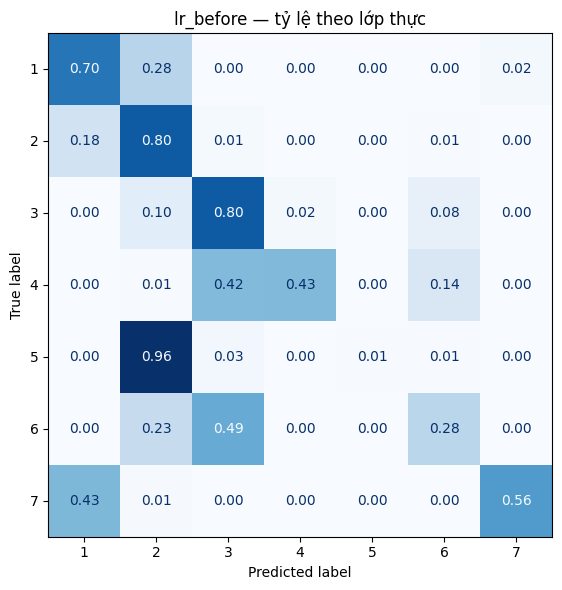

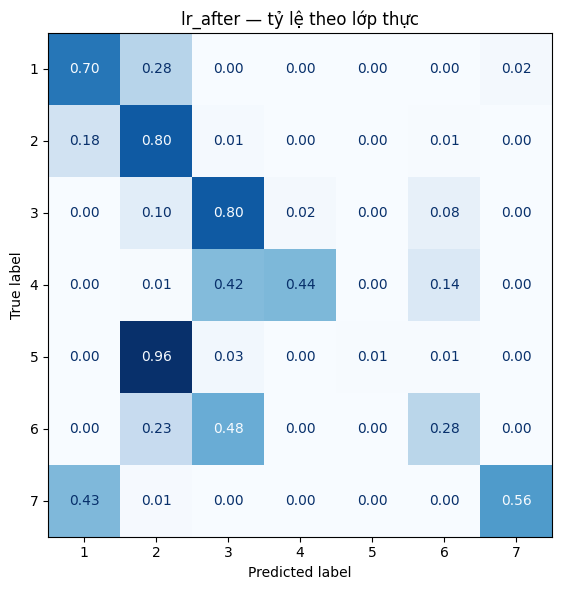

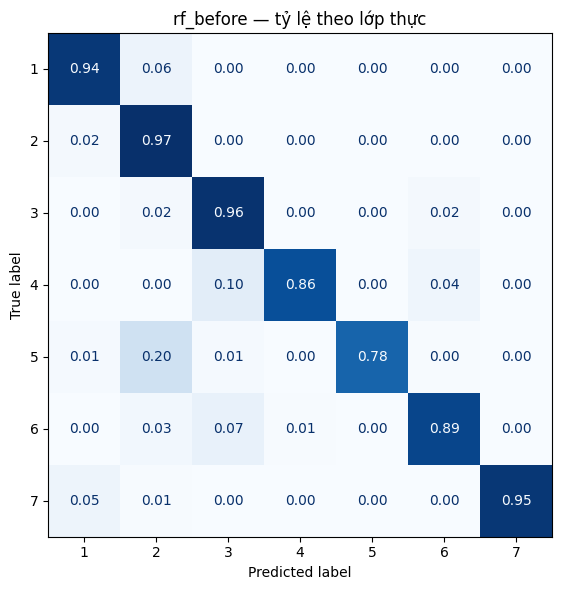

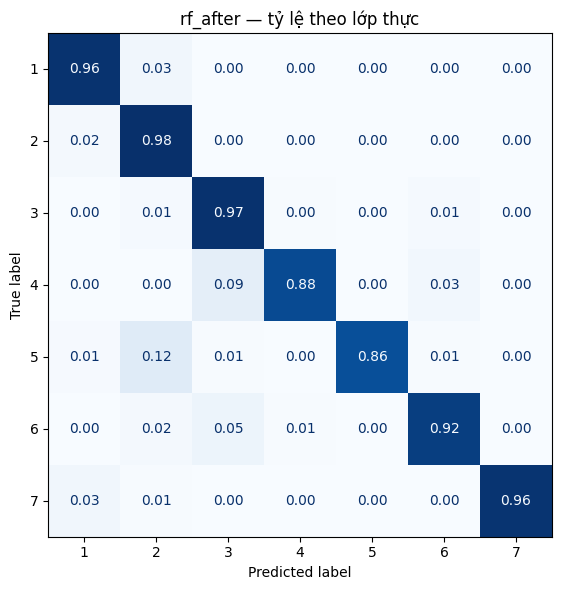

In [25]:
for name, y_pred in predictions.items():
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels,
                                            normalize='true', cmap='Blues', ax=ax,
                                            values_format='.2f', colorbar=False)
    ax.set_title(name + ' — tỷ lệ theo lớp thực')
    plt.tight_layout()
    plt.show()

### 7.5. Bảng so sánh bốn mô hình trong cùng thực nghiệm

In [26]:
fit_times = {'lr_before': fit_time_lr, 'lr_after': grid_lr.refit_time_,
             'rf_before': fit_time_rf, 'rf_after': grid_rf.refit_time_}
cv_means = {'lr_before': cv_baseline['LR']['test_f1_macro'].mean(),
            'lr_after': grid_lr.best_score_,
            'rf_before': cv_baseline['RF']['test_f1_macro'].mean(),
            'rf_after': grid_rf.best_score_}
cv_stds = {'lr_before': cv_baseline['LR']['test_f1_macro'].std(),
           'lr_after': grid_lr.cv_results_['std_test_score'][grid_lr.best_index_],
           'rf_before': cv_baseline['RF']['test_f1_macro'].std(),
           'rf_after': grid_rf.cv_results_['std_test_score'][grid_rf.best_index_]}
rows = []
for name, y_pred in predictions.items():
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, y_pred),
                 'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
                 'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
                 'recall_macro': recall_score(y_test, y_pred, average='macro', zero_division=0),
                 'f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
                 'cv_f1_macro_mean': cv_means[name], 'cv_f1_macro_std': cv_stds[name],
                 'fit_seconds': fit_times[name], 'predict_seconds_median': predict_times[name],
                 'grid_search_total_seconds': search_time_lr if name.startswith('lr_') else search_time_rf})

comparison = pd.DataFrame(rows)
assert set(comparison['model']) == {'lr_before', 'lr_after', 'rf_before', 'rf_after'}
display(comparison.round(4))

,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,cv_f1_macro_mean,cv_f1_macro_std,fit_seconds,predict_seconds_median,grid_search_total_seconds
0,lr_before,0.7233,0.5089,0.5910,0.5089,0.5300,0.5325,0.0043,89.9480,0.2277,2637.7950
1,lr_after,0.7235,0.5103,0.5909,0.5103,0.5312,0.5343,0.0039,103.2244,0.2350,2637.7950
2,rf_before,0.9538,0.9064,0.9466,0.9064,0.9249,0.9117,0.0003,167.8231,4.7968,12719.5829
3,rf_after,0.9681,0.9337,0.9541,0.9337,0.9435,0.9328,0.0008,789.6306,7.8812,12719.5829


### 7.6. Đặc trưng quan trọng của RF

,0
Elevation,0.277395
Horizontal_Distance_To_Roadways,0.134604
Horizontal_Distance_To_Fire_Points,0.132525
Horizontal_Distance_To_Hydrology,0.059526
Vertical_Distance_To_Hydrology,0.049518
Wilderness_Area4,0.038799
Hillshade_Noon,0.036665
Aspect,0.034715
Hillshade_9am,0.032282
Hillshade_3pm,0.028797


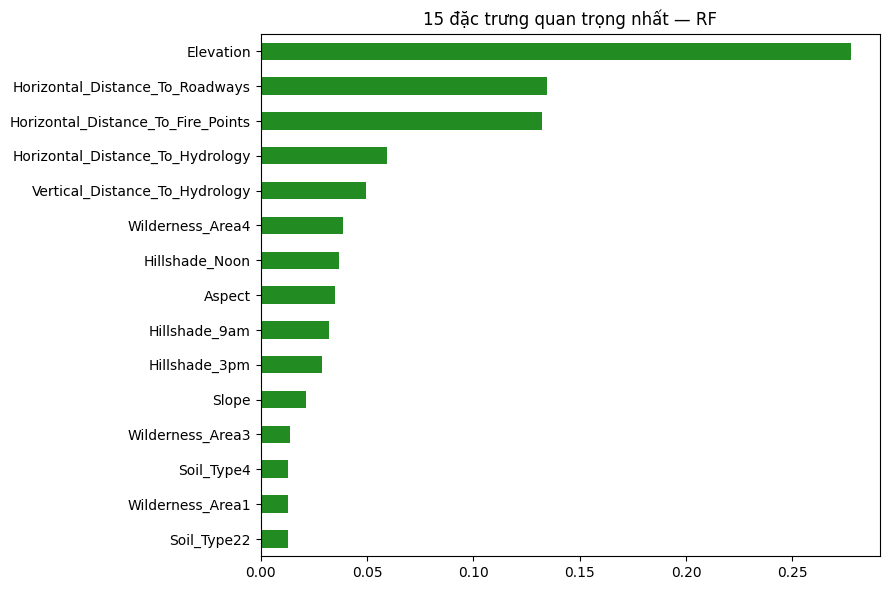

In [27]:
importance = pd.Series(best_rf.named_steps['clf'].feature_importances_, index=features)
importance = importance.sort_values(ascending=False)
display(importance.head(15))
importance.head(15).sort_values().plot.barh(figsize=(9, 6), color='forestgreen')
plt.title('15 đặc trưng quan trọng nhất — RF')
plt.tight_layout()
plt.show()

### 7.7. Nhận xét kết quả
- So sánh Macro-F1, Accuracy và Recall từng lớp; không chỉ nhìn Accuracy vì dữ liệu mất cân bằng.
- So sánh trước/sau theo số thực tế. Nếu LR chọn C=1.0 và class_weight=None thì cấu hình tối ưu trùng baseline;
  điểm có thể giống nhau, còn thời gian đo hai lần fit có thể khác nhau.
- Chọn cấu hình/thuật toán theo CV, không dùng Test để tinh chỉnh lại. Importance không khẳng định nhân quả.
- Hai lưới cùng 16 cấu hình nhưng chi phí mỗi fit khác nhau; báo riêng thời gian tìm kiếm và refit cuối.
- Kết luận giới hạn ở một seed, một split ngẫu nhiên; chưa chứng minh hiệu quả tại vùng địa lý mới.

In [28]:
cv_selection = pd.DataFrame({'model': ['lr_after', 'rf_after'],
                              'cv_f1_macro': [grid_lr.best_score_, grid_rf.best_score_]})
selected = cv_selection.sort_values('cv_f1_macro', ascending=False).iloc[0]
print('Mô hình được chọn theo CV:', selected['model'])
display(cv_selection)

Mô hình được chọn theo CV: rf_after


,model,cv_f1_macro
0,lr_after,0.534284
1,rf_after,0.932816


## Phụ lục. Lưu kết quả và mô hình
Phần chính đã trình bày xong toàn bộ thực nghiệm. Các cell dưới chỉ lưu metadata,
xác thực dữ liệu/split và xuất tệp. Không nạp số RF lịch sử để điền vào bảng so sánh mới.
Mỗi lần lưu tạo thư mục riêng; các kết quả cũ được giữ nguyên.

In [29]:
import hashlib
import json
import platform
import sys
import joblib

RESULTS_ROOT = Path('Covertype_RF_LR')
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT = RESULTS_ROOT / 'runs' / RUN_ID
OUT.mkdir(parents=True, exist_ok=True)

h = hashlib.sha256()
h.update(np.ascontiguousarray(X, dtype=np.float32).tobytes())
h.update(np.ascontiguousarray(y, dtype=np.int8).tobytes())
h.update(json.dumps(features, ensure_ascii=False).encode('utf-8'))
fingerprint = h.hexdigest()
# Fingerprint dùng tên cột UCI hiện tại; không so với tên cột sklearn của phiên cũ.
split_hash = hashlib.sha256(train_idx.tobytes() + test_idx.tobytes()).hexdigest()
fold_id = np.full(len(y_train), -1, dtype=np.int8)
for fold, (_, valid_pos) in enumerate(cv_splits):
    fold_id[valid_pos] = fold
fold_hash = hashlib.sha256(fold_id.tobytes()).hexdigest()
print('Thư mục kết quả:', OUT.resolve())

Thư mục kết quả: /content/Covertype_RF_LR/runs/20261113_132932_419147


In [30]:
environment = {'run_id': RUN_ID, 'output_dir': str(OUT.resolve()), 'python': sys.version,
               'platform': platform.platform(), 'sklearn': sklearn.__version__,
               'numpy': np.__version__, 'pandas': pd.__version__, 'seed': SEED,
               'test_size': 0.2, 'cv_folds': N_SPLITS, 'thread_budget': N_JOBS,
               'run_lr': True, 'run_rf': True, 'data_fingerprint': fingerprint,
               'split_sha256': split_hash, 'fold_sha256': fold_hash,
               'lr_param_grid': param_grid_lr, 'rf_param_grid': param_grid_rf}
comparison['run_id'] = RUN_ID
comparison['source'] = 'current_run'
comparison['sklearn_version'] = sklearn.__version__
comparison['data_fingerprint'] = fingerprint
comparison['split_sha256'] = split_hash
comparison['fold_sha256'] = fold_hash
comparison.to_csv(OUT / 'same_experiment_comparison.csv', index=False, encoding='utf-8-sig')
comparison.to_csv(OUT / 'current_run_results.csv', index=False, encoding='utf-8-sig')

np.savez_compressed(OUT / 'shared_split.npz', train_idx=train_idx, test_idx=test_idx,
                    seed=SEED, test_size=0.2, fingerprint=fingerprint)
pd.DataFrame({'source_row_id': train_idx, 'label': y_train.to_numpy(),
              'validation_fold': fold_id}).to_csv(OUT / 'train_cv_folds.csv', index=False)
df_grid_lr.to_csv(OUT / 'lr_grid_search_results.csv', index=False)
df_grid_rf.to_csv(OUT / 'grid_search_results.csv', index=False)

In [31]:
for name, model in models.items():
    joblib.dump({'model': model, 'feature_names': features, 'data_fingerprint': fingerprint,
                 'split_sha256': split_hash, 'fold_sha256': fold_hash,
                 'sklearn_version': sklearn.__version__}, OUT / f'{name}.joblib', compress=3)
    pd.DataFrame({'source_row_id': test_idx, 'y_true': y_test.to_numpy(),
                  'y_pred': predictions[name]}).to_csv(OUT / f'{name}_predictions.csv', index=False)
    report = classification_report(y_test, predictions[name], labels=labels,
                                    target_names=class_names, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'{name}_classification_report.csv', encoding='utf-8-sig')

metadata = {
    'environment.json': environment,
    'data_manifest.json': {'source': 'ucimlrepo.fetch_ucirepo(id=31)', 'feature_names': features,
                           'n_samples': len(df), 'n_features': len(features)},
    'lr_best_params.json': grid_lr.best_params_,
    'best_params.json': grid_rf.best_params_,
    'comparison_status.json': {'run_id': RUN_ID, 'complete': True},
    'selected_model_by_cv.json': {'model': selected['model'], 'selection_metric': 'CV f1_macro',
                                 'cv_f1_macro': float(selected['cv_f1_macro']), 'run_id': RUN_ID}
}
for filename, value in metadata.items():
    (OUT / filename).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')
(RESULTS_ROOT / 'latest_run.json').write_text(json.dumps({
    'run_id': RUN_ID, 'output_dir': str(OUT.resolve()), 'run_lr': True, 'run_rf': True}, indent=2), encoding='utf-8')
print('Đã lưu bốn Pipeline và bảng so sánh:', OUT.resolve())

Đã lưu bốn Pipeline và bảng so sánh: /content/Covertype_RF_LR/runs/20261113_132932_419147
